<a href="https://colab.research.google.com/github/rutvikarnik5/Microsoft-4B-groundwater-timeseries-prediction-using-AI/blob/main/Microsoft_4B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Downloading the Data

In [ ]:
!git clone https://github.com/Break-Through-Tech/Microsoft-4B-groundwater-timeseries-prediction-using-AI.git

Cloning into 'Microsoft-4B-groundwater-timeseries-prediction-using-AI'...
remote: Enumerating objects: 61, done.
remote: Counting objects: 100% (61/61), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 61 (delta 29), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (61/61), 8.02 MiB | 1.78 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [ ]:
%cd Microsoft-4B-groundwater-timeseries-prediction-using-AI

/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI


In [ ]:
%cd notebooks

/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI/notebooks


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Daily Dataset

In [ ]:
df_daily = pd.read_csv("/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI/data/svn_regional_53_wells_daily_2019_2023.csv")
df_daily.head()

/tmp/ipykernel_4424/3712712724.py:1: DtypeWarning: Columns (58) have mixed types. Specify dtype option on import or set low_memory=False.
  df_daily = pd.read_csv("/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI/data/svn_regional_53_wells_daily_2019_2023.csv")


,GROW_ID,interval,date,year,month,aggregated_from_n_values,outliers_change_points,plateaus,groundwater_water_level_elevation_m_asl,precipitation_mswep_mm_year-1,...,permeability_0-100_m_m-2,total_porosity_0-100_m_fraction,soil_texture_0-30_cm_class,soil_texture_30-200_cm_class,soil_saturated_conductivity_0-30_cm_cm_d-1,soil_saturated_conductivity_30-200_cm_cm_d-1,distance_perennial_streams_m,drainage_density_m-1,main_landuse_class,distance_to_cluster_center_km
0,GROW-18108201772,d,2019-01-01,2019,2019-01,NaN,False,0,304.83,45.625,...,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
1,GROW-18108201772,d,2019-01-02,2019,2019-01,NaN,False,0,304.79,0.000,...,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
2,GROW-18108201772,d,2019-01-03,2019,2019-01,NaN,False,0,304.73,0.000,...,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
3,GROW-18108201772,d,2019-01-04,2019,2019-01,NaN,False,0,304.68,0.000,...,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
4,GROW-18108201772,d,2019-01-05,2019,2019-01,NaN,False,0,304.64,0.000,...,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858


In [ ]:
df_daily.shape

(96778, 65)

In [ ]:
df_daily.dtypes

,0
GROW_ID,object
interval,object
date,object
year,int64
month,object
...,...
soil_saturated_conductivity_30-200_cm_cm_d-1,float64
distance_perennial_streams_m,float64
drainage_density_m-1,float64
main_landuse_class,object


## Daily Dataset Cleaning

In [ ]:
# missing data for daily set

null_counts = df_daily.isnull().sum()
result = null_counts[null_counts > 0]
result

,0
aggregated_from_n_values,96778
groundwater_water_level_elevation_m_asl,5
precipitation_gpcc_mm_year-1,58035
ndvi_ratio,1114
withdrawal_industrial_m3_year-1,38690
withdrawal_domestic_m3_year-1,38690
urban_area_fraction,38690
pastures_fraction,38690
cropland_rainfed_fraction,38690
cropland_irrigated_fraction,38690


In [ ]:
nan_col_types = df_daily[result.index].dtypes
nan_col_types

# What data types are missing in the daily dataset?

,0
aggregated_from_n_values,float64
groundwater_water_level_elevation_m_asl,float64
precipitation_gpcc_mm_year-1,float64
ndvi_ratio,float64
withdrawal_industrial_m3_year-1,float64
withdrawal_domestic_m3_year-1,float64
urban_area_fraction,float64
pastures_fraction,float64
cropland_rainfed_fraction,float64
cropland_irrigated_fraction,float64


In [ ]:
df_daily = df_daily.drop(columns=['aggregated_from_n_values', 'status', 'aquifer_name', 'confinement'], axis=1)

In [ ]:
dfdaily_missing_cols = df_daily.columns[df_daily.isna().any()]
numeric_cols = df_daily[dfdaily_missing_cols].select_dtypes(include=np.number).columns
df_interpolated = df_daily[numeric_cols].interpolate()
df_daily[numeric_cols] = df_interpolated

In [ ]:
df_daily.columns[df_daily.isna().any()]

Index(['soil_texture_30-200_cm_class'], dtype='object')

In [ ]:
df_daily.shape

(96778, 61)

In [ ]:
# y = groundwater_water_level_elevation_m_asl

## Standardizing Categorical Variables

In [ ]:
# Identify categorical columns
df_daily.select_dtypes(include=['object'])

,GROW_ID,interval,date,month,name,feature_type,purpose,country,organisation,license,starting_date,ending_date,trend_direction,reference_point,koeppen_geiger_class,hydrobelt_class,aquifer_type_class,soil_texture_0-30_cm_class,soil_texture_30-200_cm_class,main_landuse_class
0,GROW-18108201772,d,2019-01-01,2019-01,Mengeš (Mp-0275),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,decreasing,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Fine,Medium,forests_and_natural_vegetation
1,GROW-18108201772,d,2019-01-02,2019-01,Mengeš (Mp-0275),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,decreasing,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Fine,Medium,forests_and_natural_vegetation
2,GROW-18108201772,d,2019-01-03,2019-01,Mengeš (Mp-0275),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,decreasing,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Fine,Medium,forests_and_natural_vegetation
3,GROW-18108201772,d,2019-01-04,2019-01,Mengeš (Mp-0275),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,decreasing,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Fine,Medium,forests_and_natural_vegetation
4,GROW-18108201772,d,2019-01-05,2019-01,Mengeš (Mp-0275),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,decreasing,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Fine,Medium,forests_and_natural_vegetation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96773,GROW-18112547287,d,2023-12-27,2023-12,Lj - Sojerjeva (0631),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2012-01-01,2023-12-31,no trend,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Medium,NaN,forests_and_natural_vegetation
96774,GROW-18112547287,d,2023-12-28,2023-12,Lj - Sojerjeva (0631),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2012-01-01,2023-12-31,no trend,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Medium,NaN,forests_and_natural_vegetation
96775,GROW-18112547287,d,2023-12-29,2023-12,Lj - Sojerjeva (0631),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2012-01-01,2023-12-31,no trend,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Medium,NaN,forests_and_natural_vegetation
96776,GROW-18112547287,d,2023-12-30,2023-12,Lj - Sojerjeva (0631),Water well,Observation / monitoring,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMAT...",Attribution 4.0 International (CC BY 4.0),2012-01-01,2023-12-31,no trend,Water level elevation a.m.s.l.,Cfb,Mid-latitude,karst,Medium,NaN,forests_and_natural_vegetation


In [ ]:
df_daily[['trend_direction', 'soil_texture_0-30_cm_class', 'soil_texture_30-200_cm_class']].dtypes


,0
trend_direction,object
soil_texture_0-30_cm_class,object
soil_texture_30-200_cm_class,object


In [ ]:
df_daily['trend_direction'].unique()

array(['decreasing', 'no trend'], dtype=object)

In [ ]:
df_daily['soil_texture_0-30_cm_class'].unique()

array(['Fine', 'Medium'], dtype=object)

In [ ]:
df_daily['soil_texture_30-200_cm_class'].unique()

array(['Medium', nan, 'Fine'], dtype=object)

In [ ]:
df_daily_encoded = df_daily.copy()

In [ ]:
# Columns to encode
to_encode = ['trend_direction', 'soil_texture_0-30_cm_class', 'soil_texture_30-200_cm_class']

for column in to_encode:
  # Create dummy columns
  df_daily_temp = pd.get_dummies(df_daily_encoded[column], prefix=column)

  # Add dummy columns to dataset
  df_daily_encoded = df_daily_encoded.join(df_daily_temp)

  # Drop original column
  df_daily_encoded.drop(columns=column, inplace=True)

# Check whether the loop was successful
df_daily_encoded.columns

Index(['GROW_ID', 'interval', 'date', 'year', 'month',
       'outliers_change_points', 'plateaus',
       'groundwater_water_level_elevation_m_asl',
       'precipitation_mswep_mm_year-1', 'precipitation_gpcc_mm_year-1',
       'potential_evapotranspiration_era5_mm_year-1',
       'potential_evapotranspiration_gleam_mm_year-1',
       'actual_evapotranspiration_mm_year-1', 'interception_mm_year-1',
       'air_temperature_°C', 'snow_depth_m',
       'days_with_snow_cover_days_year-1', 'ndvi_ratio',
       'lai_low_vegetation_ratio', 'lai_high_vegetation_ratio',
       'withdrawal_industrial_m3_year-1', 'withdrawal_domestic_m3_year-1',
       'urban_area_fraction', 'pastures_fraction', 'cropland_rainfed_fraction',
       'cropland_irrigated_fraction', 'forests_natural_vegetation_fraction',
       'original_ID_groundwater', 'name', 'feature_type', 'purpose',
       'latitude', 'longitude', 'country', 'organisation', 'license',
       'starting_date', 'ending_date', 'length_years', 'auto

## Daily Feature Engineering

In [ ]:
## feature engineering
# new cols from raw ones so the model sees the pattern (ex: 90 day rain not just today)

In [ ]:
# date to datetime, sort by well + date
df_daily_fe = df_daily_encoded.copy()
df_daily_fe['date'] = pd.to_datetime(df_daily_fe['date'])
df_daily_fe.sort_values(by=['GROW_ID', 'date'], inplace=True)

In [ ]:
# month + recharge season flag (oct-mar), wells fill up in winter
df_daily_fe['month_num'] = df_daily_fe['date'].dt.month
df_daily_fe['is_recharge_season'] = df_daily_fe['month_num'].isin([10, 11, 12, 1, 2, 3]).astype(int)

In [ ]:
# precip mm/year -> mm/day
df_daily_fe['precip_mm'] = df_daily_fe['precipitation_mswep_mm_year-1'] / 365.25

In [ ]:
# rain minus evaporation
df_daily_fe['water_balance_mm'] = df_daily_fe['precip_mm'] - df_daily_fe['actual_evapotranspiration_mm_year-1'] / 365.25

In [ ]:
# rolling sums per well (30 / 90 days) so windows dont mix wells
target = 'groundwater_water_level_elevation_m_asl'
grouped_daily = df_daily_fe.groupby('GROW_ID')

df_daily_fe['precip_sum_30'] = grouped_daily['precip_mm'].transform(lambda x: x.rolling(30, min_periods=1).sum())
df_daily_fe['precip_sum_90'] = grouped_daily['precip_mm'].transform(lambda x: x.rolling(90, min_periods=1).sum())
df_daily_fe['water_balance_sum_90'] = grouped_daily['water_balance_mm'].transform(lambda x: x.rolling(90, min_periods=1).sum())

In [ ]:
# past levels + how much it moved
df_daily_fe['level_lag_1'] = grouped_daily[target].shift(1)
df_daily_fe['level_lag_7'] = grouped_daily[target].shift(7)
df_daily_fe['level_lag_30'] = grouped_daily[target].shift(30)
df_daily_fe['level_diff_7'] = grouped_daily[target].diff(7)

# level vs the well's own avg, wells sit at diff elevations
df_daily_fe['level_anomaly'] = df_daily_fe[target] - df_daily_fe['groundwater_mean_m']

In [ ]:
# drop first rows per well, no history so lags are NaN
df_daily_fe = df_daily_fe.dropna(subset=['level_lag_30'])
print(df_daily_fe.shape)

(95188, 76)


In [ ]:
df_daily = df_daily_fe.copy()

## Daily Visualizations

In [ ]:
df_daily.describe()

,date,year,plateaus,groundwater_water_level_elevation_m_asl,precipitation_mswep_mm_year-1,precipitation_gpcc_mm_year-1,potential_evapotranspiration_era5_mm_year-1,potential_evapotranspiration_gleam_mm_year-1,actual_evapotranspiration_mm_year-1,interception_mm_year-1,...,precip_mm,water_balance_mm,precip_sum_30,precip_sum_90,water_balance_sum_90,level_lag_1,level_lag_7,level_lag_30,level_diff_7,level_anomaly
count,95188,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,...,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000,95188.000000
mean,2021-07-16 12:00:00,2021.032851,0.305070,311.504951,1567.334721,1655.535046,1318.754150,846.686616,656.263477,97.409349,...,4.291129,2.494377,128.884333,376.974936,215.841251,311.503676,311.495399,311.458618,0.009552,-0.225251
min,2019-01-31 00:00:00,2019.000000,0.000000,270.470000,0.000000,90.120000,-16.491157,9.267370,9.089959,0.000000,...,0.000000,-6.828650,0.374743,50.153149,-91.970904,270.470000,270.470000,270.470000,-15.900000,-8.891145
25%,2020-04-23 18:00:00,2020.000000,0.000000,286.870000,0.000000,1246.782044,455.743417,270.373907,219.245955,0.000065,...,0.000000,-2.109247,82.568446,296.351707,119.431155,286.870000,286.860000,286.820000,-0.110000,-0.713316
50%,2021-07-16 12:00:00,2021.000000,0.000000,293.605000,114.062500,1643.973668,1052.685185,740.441555,587.268575,45.603837,...,0.312286,-0.484492,123.290554,382.488022,198.711730,293.605000,293.605000,293.430000,-0.040000,-0.212140
75%,2022-10-08 06:00:00,2022.000000,0.000000,334.050000,1414.375000,2089.625146,1822.833907,1328.772937,1043.866420,151.991314,...,3.872348,2.204676,162.786939,452.541603,317.570122,334.050000,334.040000,334.010000,0.050000,0.210904
max,2023-12-31 00:00:00,2023.000000,16.000000,474.200000,34492.500000,5774.400000,8466.665195,3237.025130,2494.164355,1130.846285,...,94.435318,92.561787,488.618454,854.781719,641.553423,474.200000,474.200000,474.200000,20.410000,15.515622
std,NaN,1.401776,1.332469,36.950910,3278.148497,650.883188,1117.036181,633.622763,464.653753,127.055505,...,8.975081,9.193829,69.313198,119.403201,129.084575,36.950366,36.947202,36.938201,1.046384,1.687425


In [ ]:
# Remove "level_lag_1", "level_lag_7", "level_lag_30", "level_diff_7", "level_anomaly"
df_daily_corr = df_daily.drop(["level_lag_1", "level_lag_7", "level_lag_30", "level_diff_7", "level_anomaly"], axis=1)

In [ ]:
# What features are highly correlated with each other?
numeric_cols = df_daily_corr.select_dtypes(include=[np.number]).columns
corr_matrix = df_daily_corr[numeric_cols].corr()
corr_pairs = corr_matrix.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0].sort_values(ascending=False)
print(corr_pairs.head(20))

precip_mm                                     precipitation_mswep_mm_year-1                   1.000000
precipitation_mswep_mm_year-1                 precip_mm                                       1.000000
groundwater_median_m                          groundwater_mean_m                              0.999939
groundwater_mean_m                            groundwater_median_m                            0.999939
groundwater_water_level_elevation_m_asl       groundwater_mean_m                              0.998960
groundwater_mean_m                            groundwater_water_level_elevation_m_asl         0.998960
groundwater_median_m                          groundwater_water_level_elevation_m_asl         0.998899
groundwater_water_level_elevation_m_asl       groundwater_median_m                            0.998899
withdrawal_domestic_m3_year-1                 urban_area_fraction                             0.994692
urban_area_fraction                           withdrawal_domestic_m3_year

In [ ]:
# Remove features with zero variance from the correlation matrix
corr_matrix.drop(["permeability_0-100_m_m-2", "cropland_irrigated_fraction", "total_porosity_0-100_m_fraction"], axis=1, inplace=True)
corr_matrix.drop(["permeability_0-100_m_m-2", "cropland_irrigated_fraction", "total_porosity_0-100_m_fraction"], inplace=True)

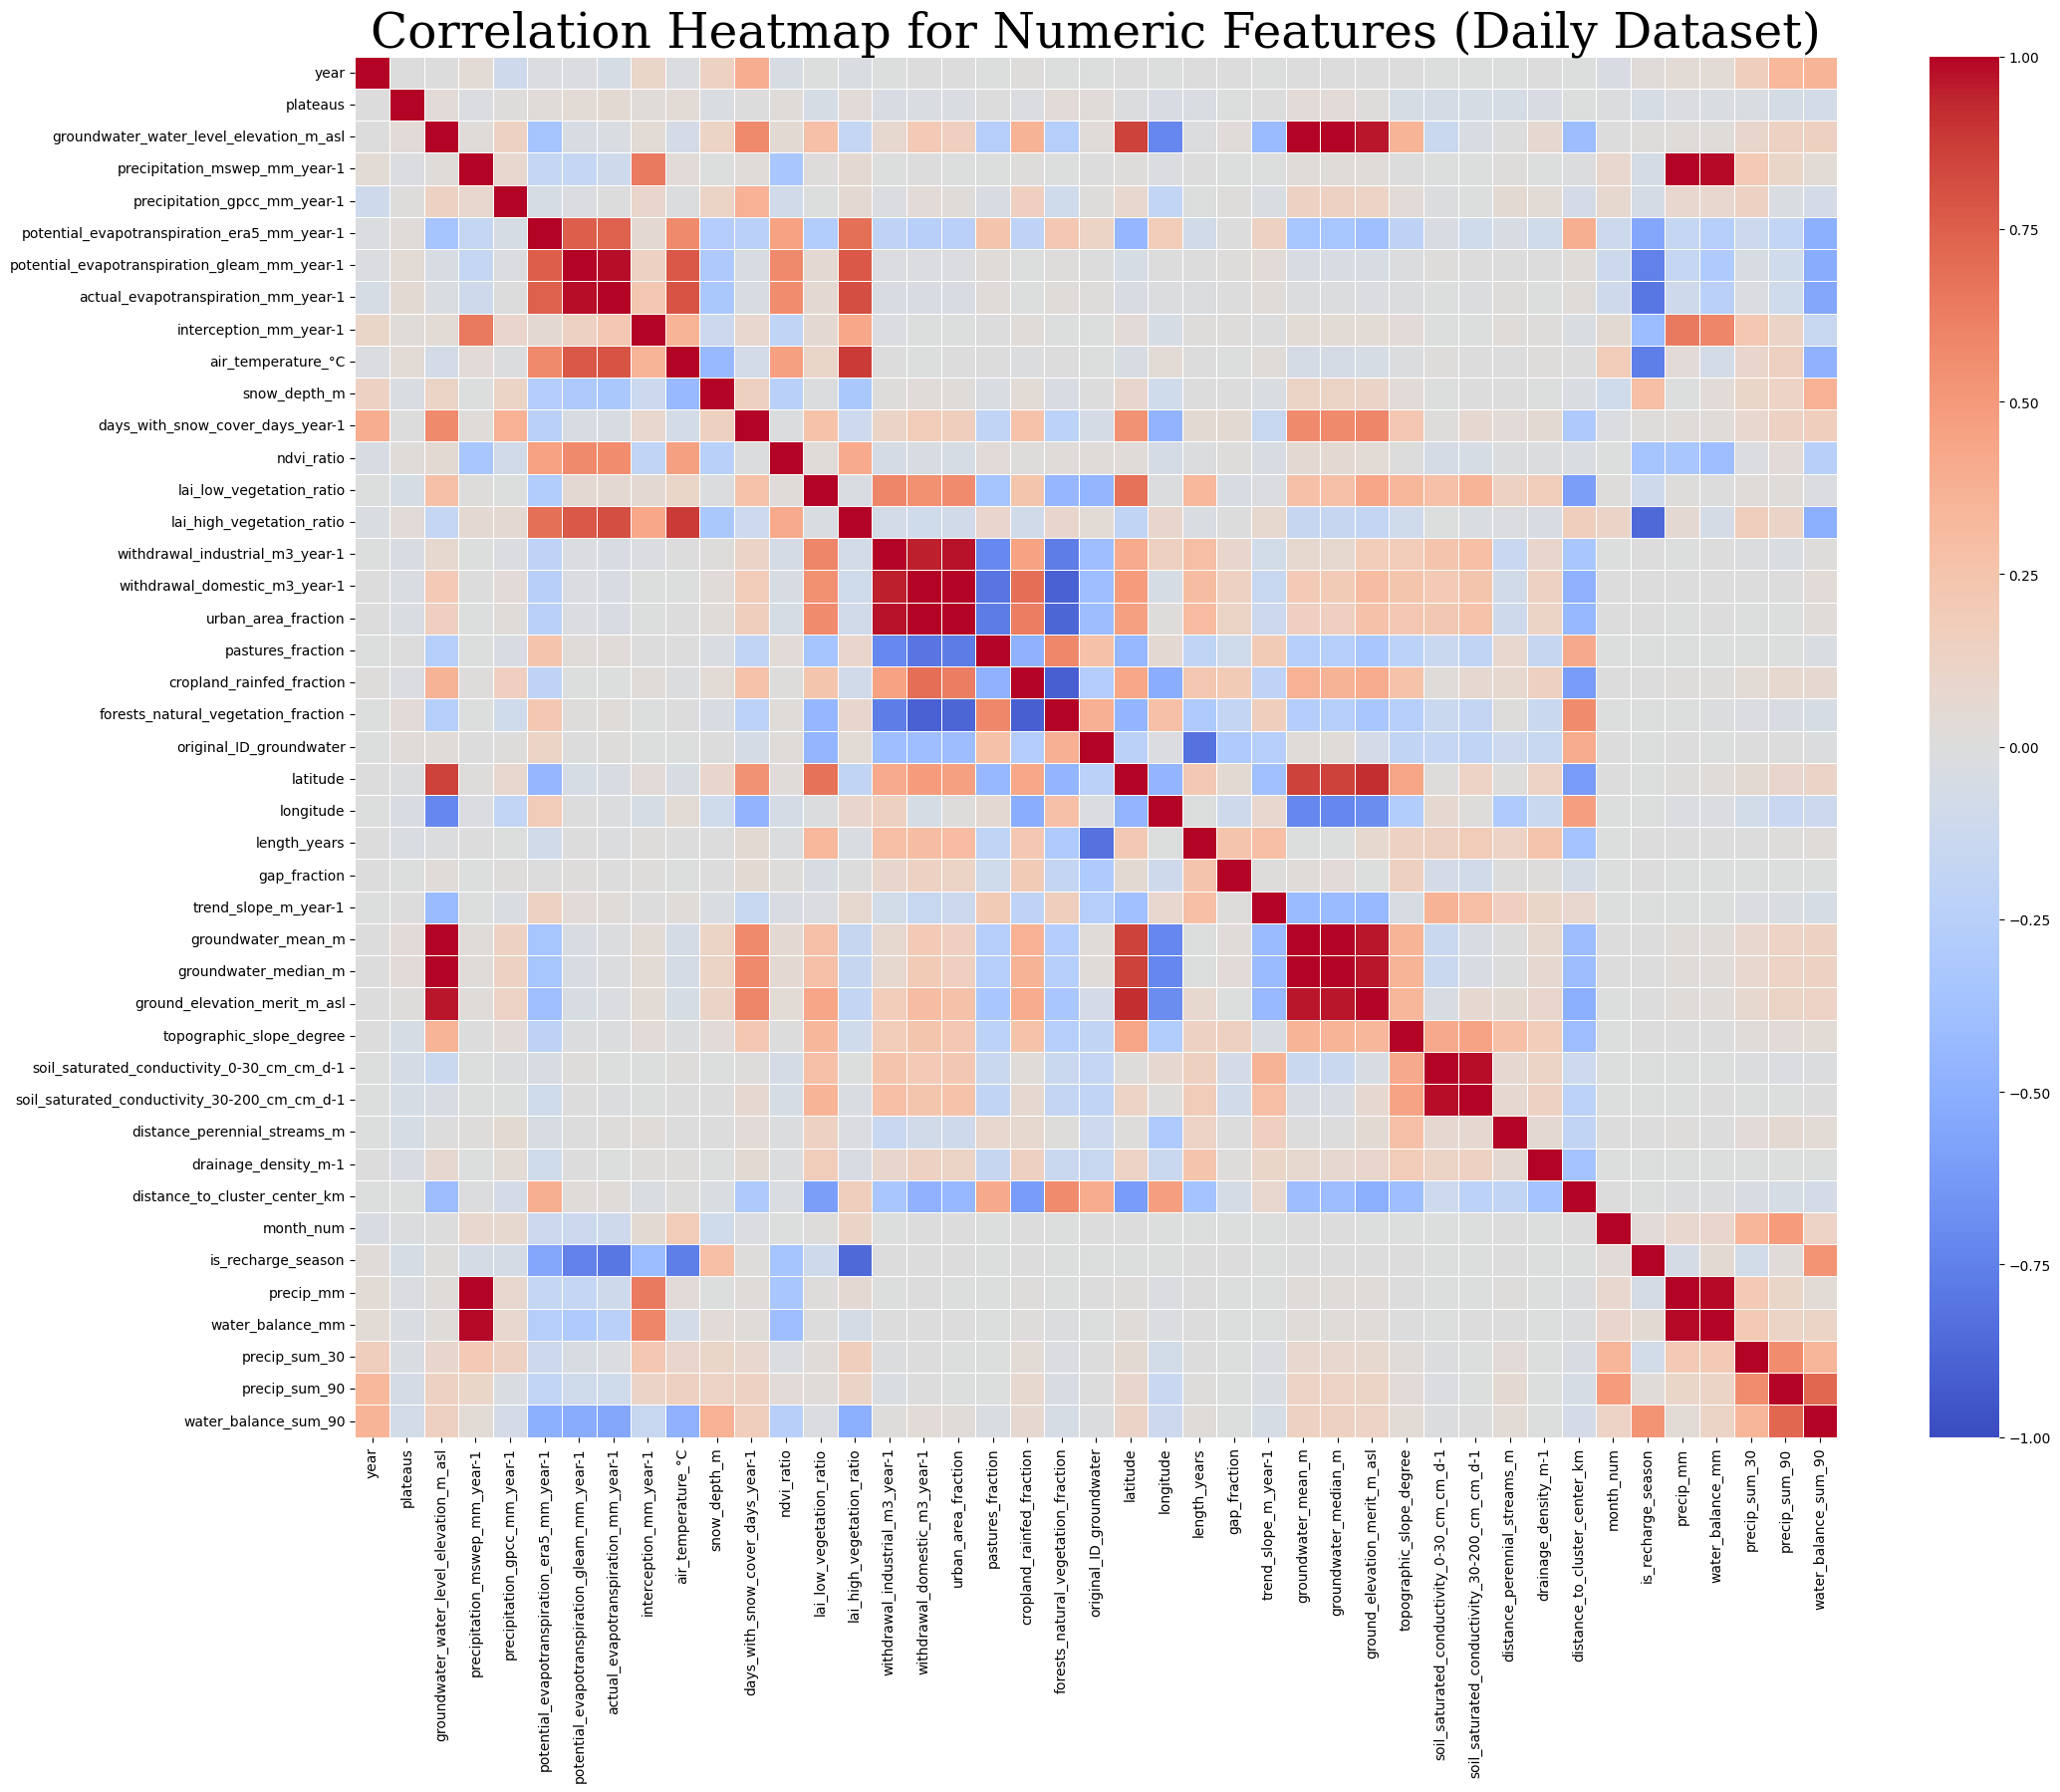

In [ ]:
# Plot a correlation heatmap
plt.figure(figsize=(24, 18))
sns.heatmap(corr_matrix,
            vmin = -1,
            vmax = 1,
            cmap = "coolwarm",
            linewidths=0.5,
            xticklabels=True,
            yticklabels=True)
plt.title("Correlation Heatmap for Numeric Features (Daily Dataset)", fontsize=35, fontname='serif')
#plt.figtext(0, 0, "Figure 1: Correlation matrix of numeric features in the daily groundwater dataset. Groundwater level elevation shows strong correlations with mean and median water table measurements, water-table trend slope, latitude, and longitude.")
plt.show()

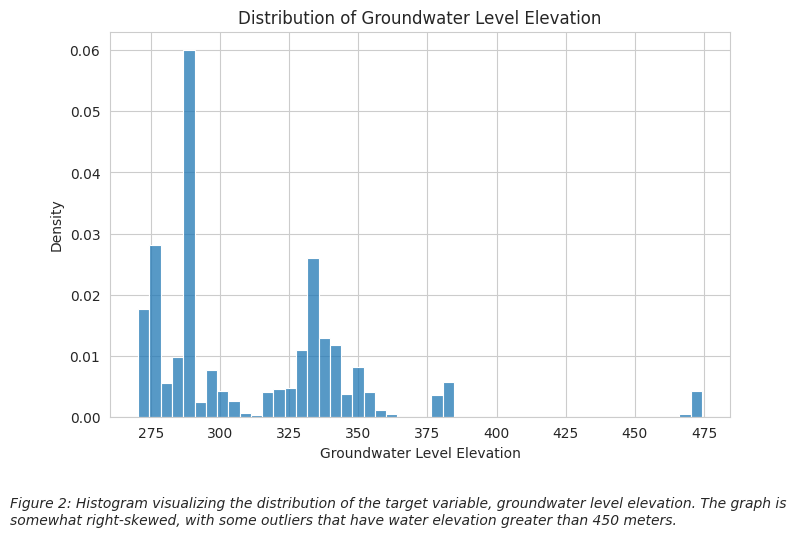

In [ ]:
sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))

sns.histplot(data=df_daily, x="groundwater_water_level_elevation_m_asl", bins=50, stat="density")
plt.title("Distribution of Groundwater Level Elevation")
plt.xlabel("Groundwater Level Elevation")
plt.ylabel("Density")
plt.figtext(0, -0.1, s="Figure 2: Histogram visualizing the distribution of the target variable, groundwater level elevation. The graph is somewhat right-skewed, with some outliers that have water elevation greater than 450 meters.", wrap=True, fontstyle='italic')
plt.show()


#plt.hist(x='groundwater_water_level_elevation_m_asl', data=df_daily, bins=50)

In [ ]:
# 53 unique well ID's
df_daily['original_ID_groundwater'].nunique()

53

In [ ]:
# There seems to be several outliers around the value of 475
#plt.boxplot(x='groundwater_water_level_elevation_m_asl', data=df_daily_fe)

In [ ]:
# All observations with 'groundwater_water_level_elevation_m_asl' greater than 400
water_level_outliers = df_daily[df_daily['groundwater_water_level_elevation_m_asl'] > 400]
# Number of unique well ID's in the subset of data: 1
print(f"Number of unique well ID's in the subset of data: {water_level_outliers['original_ID_groundwater'].nunique()}\n")
# The outliers can all be attributed to one well: 12071
print(f"The outliers can all be attributed to one well.\nWell ID: {water_level_outliers['original_ID_groundwater'].unique()[0]}")

Number of unique well ID's in the subset of data: 1

The outliers can all be attributed to one well.
Well ID: 12071


# Monthly Dataset

In [ ]:
df_monthly = pd.read_csv("/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI/data/nld_regional_105_wells_2012_2022.csv")
df_monthly.head()

,GROW_ID,interval,date,year,month,aggregated_from_n_values,outliers_change_points,plateaus,groundwater_water_level_elevation_m_asl,precipitation_mswep_mm_year-1,...,aquifer_type_class,permeability_0-100_m_m-2,total_porosity_0-100_m_fraction,soil_texture_0-30_cm_class,soil_texture_30-200_cm_class,soil_saturated_conductivity_0-30_cm_cm_d-1,soil_saturated_conductivity_30-200_cm_cm_d-1,distance_perennial_streams_m,drainage_density_m-1,main_landuse_class
0,GROW-826802686529,MS,2012-01-01,2012,2012-01,NaN,False,0,1.470642,1112.661290,...,porous,3.019952e-11,0.28,Medium,NaN,18.5119,6.4521,4300.0,0.00024,cropland_rainfed
1,GROW-826802686529,MS,2012-02-01,2012,2012-02,NaN,False,0,1.333603,263.523707,...,porous,3.019952e-11,0.28,Medium,NaN,18.5119,6.4521,4300.0,0.00024,cropland_rainfed
2,GROW-826802686529,MS,2012-03-01,2012,2012-03,NaN,False,0,1.323153,246.522177,...,porous,3.019952e-11,0.28,Medium,NaN,18.5119,6.4521,4300.0,0.00024,cropland_rainfed
3,GROW-826802686529,MS,2012-04-01,2012,2012-04,NaN,False,0,1.235456,702.625000,...,porous,3.019952e-11,0.28,Medium,NaN,18.5119,6.4521,4300.0,0.00024,cropland_rainfed
4,GROW-826802686529,MS,2012-05-01,2012,2012-05,NaN,False,0,1.221360,812.419355,...,porous,3.019952e-11,0.28,Medium,NaN,18.5119,6.4521,4300.0,0.00024,cropland_rainfed


In [ ]:
df_monthly.shape

(13860, 64)

In [ ]:
df_monthly.dtypes

,0
GROW_ID,object
interval,object
date,object
year,int64
month,object
...,...
soil_saturated_conductivity_0-30_cm_cm_d-1,float64
soil_saturated_conductivity_30-200_cm_cm_d-1,float64
distance_perennial_streams_m,float64
drainage_density_m-1,float64


## Monthly Data Cleaning

In [ ]:
# missing data for monthly set

null_counts_monthly = df_monthly.isnull().sum()
result = null_counts_monthly[null_counts_monthly > 0]
result

,0
aggregated_from_n_values,13860
precipitation_gpcc_mm_year-1,2520
potential_evapotranspiration_era5_mm_year-1,132
potential_evapotranspiration_gleam_mm_year-1,1380
actual_evapotranspiration_mm_year-1,1380
interception_mm_year-1,1380
air_temperature_°C,132
snow_depth_m,132
days_with_snow_cover_days_year-1,132
lai_low_vegetation_ratio,132


In [ ]:
nan_col_types_monthly = df_monthly[result.index].dtypes
nan_col_types_monthly

,0
aggregated_from_n_values,float64
precipitation_gpcc_mm_year-1,float64
potential_evapotranspiration_era5_mm_year-1,float64
potential_evapotranspiration_gleam_mm_year-1,float64
actual_evapotranspiration_mm_year-1,float64
interception_mm_year-1,float64
air_temperature_°C,float64
snow_depth_m,float64
days_with_snow_cover_days_year-1,float64
lai_low_vegetation_ratio,float64


In [ ]:
df_monthly = df_monthly.drop(columns=['aggregated_from_n_values', 'status', 'aquifer_name', 'confinement', 'trend_slope_m_year-1'], axis=1)

In [ ]:
dfmonthly_missing_cols = df_monthly.columns[df_monthly.isna().any()]
monthly_cols = df_monthly[dfmonthly_missing_cols].select_dtypes(include=np.number).columns
df_interpolated = df_monthly[monthly_cols].interpolate()
df_monthly[monthly_cols] = df_interpolated

In [ ]:
df_monthly.shape

(13860, 59)

In [ ]:
df_monthly.columns[df_monthly.isna().any()]

Index(['soil_texture_30-200_cm_class'], dtype='object')

## Standardizing Categorical Variables

In [ ]:
# One-hot encode categorical features, same as df_daily
df_monthly['trend_direction'].unique()

array(['no trend', 'decreasing', 'increasing'], dtype=object)

In [ ]:
df_monthly['soil_texture_0-30_cm_class'].unique()

array(['Medium', 'Coarse', 'Organic'], dtype=object)

In [ ]:
df_monthly['soil_texture_30-200_cm_class'].unique()

array([nan, 'Medium', 'Coarse', 'Fine', 'Organic'], dtype=object)

In [ ]:
df_monthly_encoded = df_monthly.copy()

In [ ]:
for column in to_encode:
  # Create dummy columns
  df_monthly_temp = pd.get_dummies(df_monthly_encoded[column], prefix=column)

  # Add dummy columns to dataset
  df_monthly_encoded = df_monthly_encoded.join(df_monthly_temp)

  # Drop original column
  df_monthly_encoded.drop(columns=column, inplace=True)

# Check whether the loop was successful
df_monthly_encoded.columns

Index(['GROW_ID', 'interval', 'date', 'year', 'month',
       'outliers_change_points', 'plateaus',
       'groundwater_water_level_elevation_m_asl',
       'precipitation_mswep_mm_year-1', 'precipitation_gpcc_mm_year-1',
       'potential_evapotranspiration_era5_mm_year-1',
       'potential_evapotranspiration_gleam_mm_year-1',
       'actual_evapotranspiration_mm_year-1', 'interception_mm_year-1',
       'air_temperature_°C', 'snow_depth_m',
       'days_with_snow_cover_days_year-1', 'ndvi_ratio',
       'lai_low_vegetation_ratio', 'lai_high_vegetation_ratio',
       'withdrawal_industrial_m3_year-1', 'withdrawal_domestic_m3_year-1',
       'urban_area_fraction', 'pastures_fraction', 'cropland_rainfed_fraction',
       'cropland_irrigated_fraction', 'forests_natural_vegetation_fraction',
       'original_ID_groundwater', 'name', 'feature_type', 'purpose',
       'latitude', 'longitude', 'country', 'organisation', 'license',
       'starting_date', 'ending_date', 'length_years', 'auto

## Monthly Feature Engineering

In [ ]:
## same as daily, windows in months (6 / 12)

In [ ]:
# date to datetime, sort by well + date
df_monthly_fe = df_monthly_encoded.copy()
df_monthly_fe['date'] = pd.to_datetime(df_monthly_fe['date'])
df_monthly_fe.sort_values(by=['GROW_ID', 'date'], inplace=True)

In [ ]:
# month + recharge season flag (oct-mar), wells fill up in winter
df_monthly_fe['month_num'] = df_monthly_fe['date'].dt.month
df_monthly_fe['is_recharge_season'] = df_monthly_fe['month_num'].isin([10, 11, 12, 1, 2, 3]).astype(int)

In [ ]:
# precip mm/year -> mm/month
df_monthly_fe['precip_mm'] = df_monthly_fe['precipitation_mswep_mm_year-1'] / 12

In [ ]:
# rain minus evaporation
df_monthly_fe['water_balance_mm'] = df_monthly_fe['precip_mm'] - df_monthly_fe['actual_evapotranspiration_mm_year-1'] / 12

In [ ]:
# rolling sums per well (6 / 12 months) so windows dont mix wells
target = 'groundwater_water_level_elevation_m_asl'
grouped_monthly = df_monthly_fe.groupby('GROW_ID')

df_monthly_fe['precip_sum_6'] = grouped_monthly['precip_mm'].transform(lambda x: x.rolling(6, min_periods=1).sum())
df_monthly_fe['precip_sum_12'] = grouped_monthly['precip_mm'].transform(lambda x: x.rolling(12, min_periods=1).sum())
df_monthly_fe['water_balance_sum_6'] = grouped_monthly['water_balance_mm'].transform(lambda x: x.rolling(6, min_periods=1).sum())

In [ ]:
# past levels + how much it moved
df_monthly_fe['level_lag_1'] = grouped_monthly[target].shift(1)
df_monthly_fe['level_lag_3'] = grouped_monthly[target].shift(3)
df_monthly_fe['level_lag_12'] = grouped_monthly[target].shift(12)
df_monthly_fe['level_diff_3'] = grouped_monthly[target].diff(3)

# level vs the well's own avg, wells sit at diff elevations
df_monthly_fe['level_anomaly'] = df_monthly_fe[target] - df_monthly_fe['groundwater_mean_m']

In [ ]:
# drop first rows per well, no history so lags are NaN
df_monthly_fe = df_monthly_fe.dropna(subset=['level_lag_12'])
print(df_monthly_fe.shape)

(12600, 78)


## Monthly Data Visualization

In [ ]:
df_monthly_fe.describe()

,date,year,plateaus,groundwater_water_level_elevation_m_asl,precipitation_mswep_mm_year-1,precipitation_gpcc_mm_year-1,potential_evapotranspiration_era5_mm_year-1,potential_evapotranspiration_gleam_mm_year-1,actual_evapotranspiration_mm_year-1,interception_mm_year-1,...,precip_mm,water_balance_mm,precip_sum_6,precip_sum_12,water_balance_sum_6,level_lag_1,level_lag_3,level_lag_12,level_diff_3,level_anomaly
count,12600,12600.000000,12600.0,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,...,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000,12600.000000
mean,2017-12-15 23:12:00,2017.500000,0.0,3.176701,802.164507,915.842790,775.216531,803.942853,592.296356,94.220484,...,66.847042,17.489013,402.522909,810.120072,106.823723,3.178851,3.182164,3.184908,-0.005464,-0.013260
min,2013-01-01 00:00:00,2013.000000,0.0,-3.463333,56.663306,81.960000,98.349043,152.144498,0.000000,11.181988,...,4.721942,-140.387307,200.465136,542.108897,-357.210733,-3.463333,-3.463333,-3.463333,-1.476270,-2.052381
25%,2015-06-23 12:00:00,2015.000000,0.0,0.928767,528.685601,606.600000,333.685808,313.224993,241.916561,65.294156,...,44.057133,-17.318621,346.934556,742.875396,-18.978307,0.928985,0.928985,0.932121,-0.186175,-0.148421
50%,2017-12-16 12:00:00,2017.500000,0.0,3.381819,739.909949,905.640000,718.511200,734.136979,504.944684,87.151962,...,61.659162,19.516106,399.330009,806.949991,116.190464,3.381819,3.387668,3.395746,-0.013925,-0.017970
75%,2020-06-08 12:00:00,2020.000000,0.0,4.826006,1033.121094,1227.206400,1158.628709,1255.120467,947.549906,115.978867,...,86.093424,52.195575,454.424591,877.575587,247.968136,4.829840,4.835160,4.832575,0.166106,0.128604
max,2022-12-01 00:00:00,2022.000000,0.0,12.997145,2406.325431,2522.400000,2189.092508,2273.283826,1764.859379,344.214686,...,200.527119,194.090222,757.115395,1282.251476,683.947777,12.997145,12.997145,13.101667,1.422326,1.049236
std,NaN,2.872395,0.0,3.147863,384.462635,398.662265,460.965442,495.876765,382.725828,40.923442,...,32.038553,49.321591,80.083783,103.433129,182.537071,3.148612,3.149820,3.150509,0.304929,0.253912


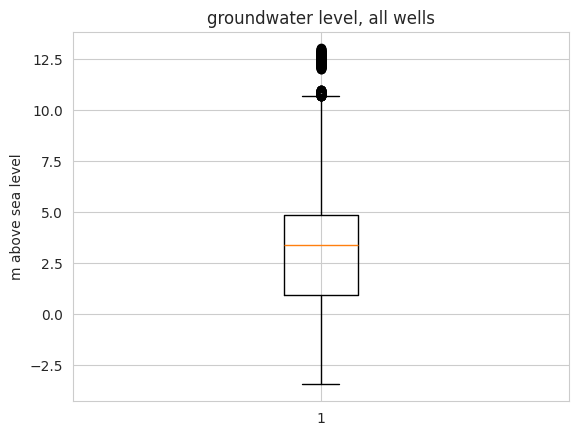

In [ ]:
plt.boxplot(df_monthly_fe[target])
plt.title('groundwater level, all wells')
plt.ylabel('m above sea level')
plt.show()

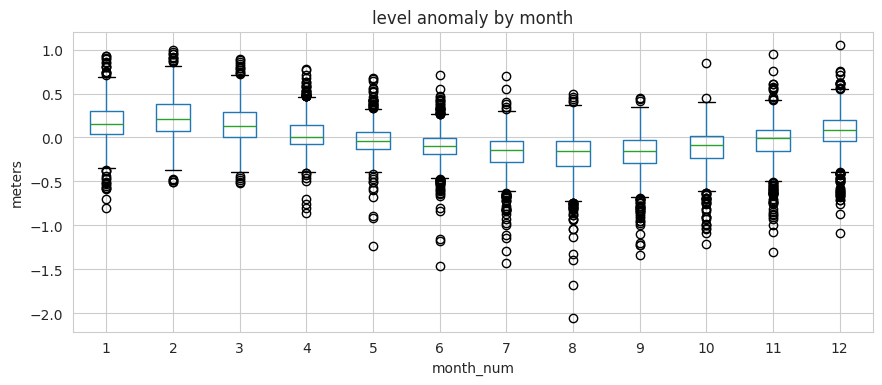

In [ ]:
# level vs each well's normal, by month
df_monthly_fe.boxplot(column='level_anomaly', by='month_num', figsize=(10, 4))
plt.title('level anomaly by month')
plt.suptitle('')
plt.ylabel('meters')
plt.show()

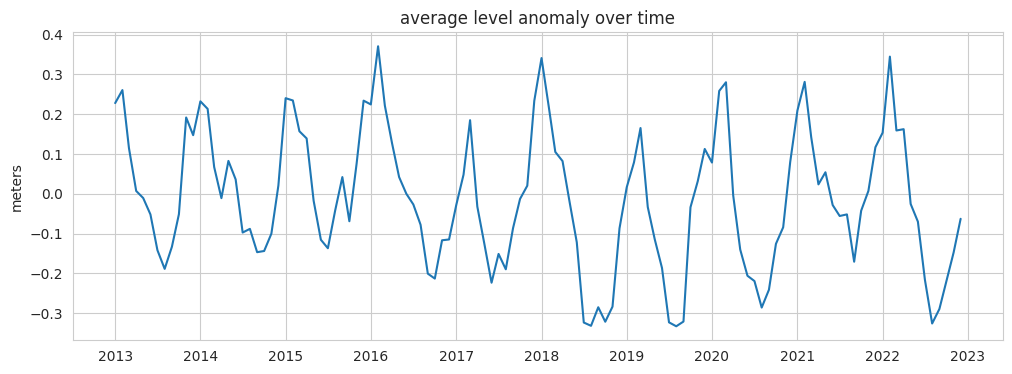

In [ ]:
# avg level over time, all wells
avg_level = df_monthly_fe.groupby('date')['level_anomaly'].mean()

plt.figure(figsize=(12, 4))
plt.plot(avg_level)
plt.title('average level anomaly over time')
plt.ylabel('meters')
plt.show()

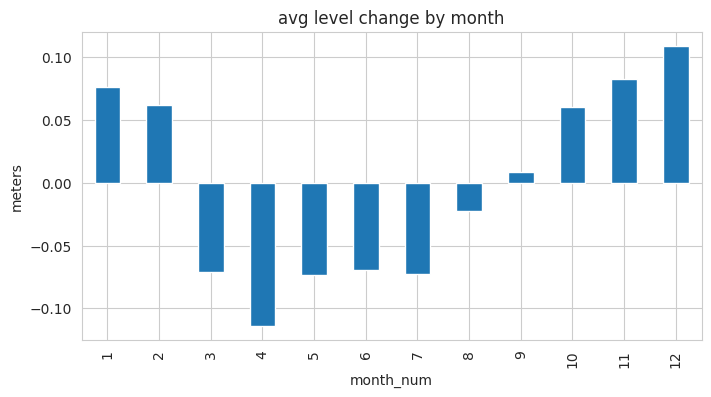

In [ ]:
#which months does the water go up or down?
df_monthly_fe = df_monthly_fe.copy()
df_monthly_fe['monthly_change'] = df_monthly_fe[target] - df_monthly_fe['level_lag_1']
change_by_month = df_monthly_fe.groupby('month_num')['monthly_change'].mean()

change_by_month.plot(kind='bar', figsize=(8, 4))
plt.title('avg level change by month')
plt.ylabel('meters')
plt.show()

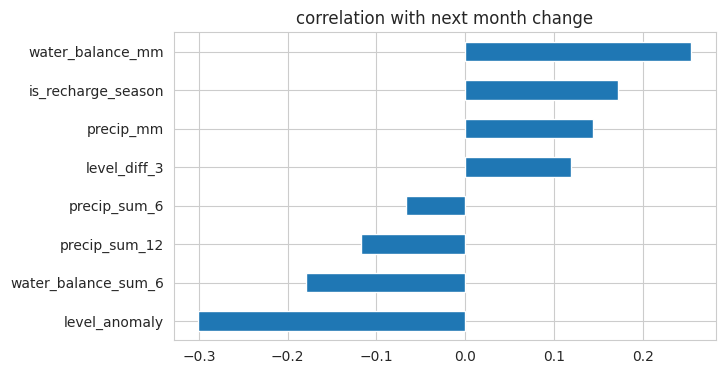

In [ ]:
# how the new features relate to next month's change
df_monthly_fe = df_monthly_fe.copy()
df_monthly_fe['next_change'] = df_monthly_fe.groupby('GROW_ID')[target].shift(-1) - df_monthly_fe[target]

new_features = ['precip_mm', 'water_balance_mm', 'precip_sum_6', 'precip_sum_12',
                'water_balance_sum_6', 'is_recharge_season', 'level_diff_3', 'level_anomaly']
corr = df_monthly_fe[new_features].corrwith(df_monthly_fe['next_change']).sort_values()

corr.plot(kind='barh', figsize=(7, 4))
plt.title('correlation with next month change')
plt.show()

# MODELS

## Linear Regression

In [ ]:
# Number of unique dates per well * number of wells
# Should match length of dataset
print(f"Number of unique dates per well * number of wells (53): {df_daily['date'].nunique() * 53}")

# Length of dataset
print(f"Above number should match length of dataset (number of rows): {df_daily.shape[0]}")

# There are 53 wells, and 1796 dates for each well
print(f"Number of unique dates per well: {df_daily['date'].nunique()}")

Number of unique dates per well * number of wells (53): 95188
Above number should match length of dataset (number of rows): 95188
Number of unique dates per well: 1796


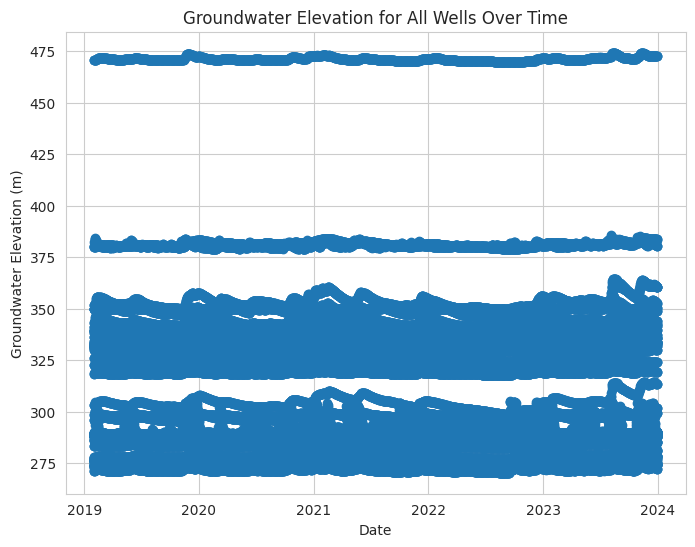

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(data=df_daily, x='date', y='groundwater_water_level_elevation_m_asl')

plt.title("Groundwater Elevation for All Wells Over Time")
plt.xlabel("Date")
plt.ylabel("Groundwater Elevation (m)")
plt.show()

The above visualization shows that depending on the well, groundwater elevation can differ. An overall linear regression model is not a good option. Rather, a model for each well makes more sense.

In [ ]:
df_daily['GROW_ID'].unique()

array(['GROW-18108201772', 'GROW-18108286252', 'GROW-18108328402',
       'GROW-18108370783', 'GROW-18108413683', 'GROW-18108456083',
       'GROW-18108540984', 'GROW-18108795755', 'GROW-18108838445',
       'GROW-18108880826', 'GROW-18108966166', 'GROW-18109008376',
       'GROW-18109055197', 'GROW-18109140047', 'GROW-18109182587',
       'GROW-18109228528', 'GROW-18109271148', 'GROW-18109313058',
       'GROW-18109439739', 'GROW-18109482609', 'GROW-18109524729',
       'GROW-18109567030', 'GROW-18109609550', 'GROW-18109651970',
       'GROW-18109693920', 'GROW-18109735871', 'GROW-18109778461',
       'GROW-18109820541', 'GROW-18110417734', 'GROW-18110502185',
       'GROW-18110544165', 'GROW-18110628036', 'GROW-18110755396',
       'GROW-18110883007', 'GROW-18110925537', 'GROW-18110968198',
       'GROW-18111524521', 'GROW-18111566581', 'GROW-18111609261',
       'GROW-18111651612', 'GROW-18111693462', 'GROW-18111735652',
       'GROW-18111777393', 'GROW-18111903853', 'GROW-181119490

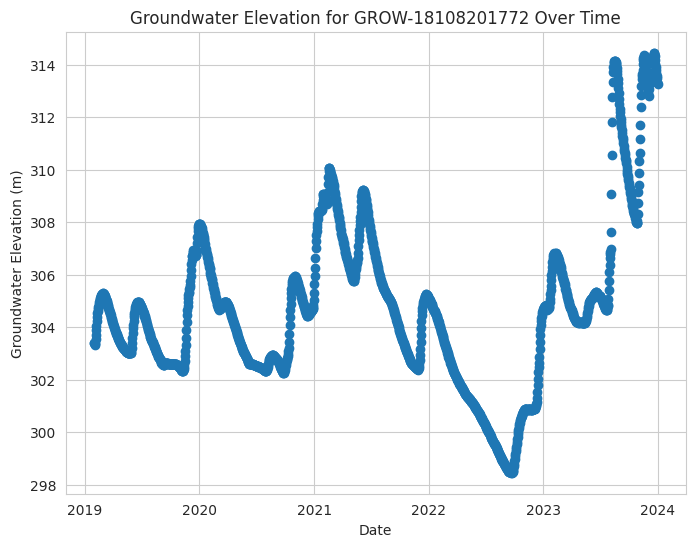

In [ ]:
# Group by well
well_groups = df_daily.groupby('GROW_ID')

well_1 = well_groups.get_group('GROW-18108201772').copy()

plt.figure(figsize=(8, 6))
plt.scatter(data=well_1, x='date', y='groundwater_water_level_elevation_m_asl')
plt.title("Groundwater Elevation for GROW-18108201772 Over Time")
plt.xlabel("Date")
plt.ylabel("Groundwater Elevation (m)")
plt.show()


In [ ]:
# Model for Well 1:

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Sort by date
well_1 = well_1.sort_values('date').copy()

# Create a sequential "time" variable:
well_1['Time'] = np.arange(len(well_1.index))

# Create a delta variable: change in groundwater elevation from yesterday to today
well_1['delta'] = well_1['groundwater_water_level_elevation_m_asl'].diff()
well_1 = well_1.dropna(subset=['delta'])

In [ ]:
# Training and Testing Split
# Training Dataset: Jan 2019 - Dec 2022
# Testing Dataset: 2023
# Approximately a 80-20 split
train = well_1.loc[well_1['date'] <= "2022-12-31", :]
test = well_1.loc[well_1['date'] >= "2023-01-01", :]

In [ ]:
# Feature Selection
# Keep only certain columns, based on how many have more than 1 unique value and which ones were used to create new features during feature engineering:

# Select numeric features only
well_1 = well_1.select_dtypes(include='number')

# Which ones only have one unique value (constant)
col_to_drop = well_1.loc[:, well_1.nunique() == 1].columns
# Drop those
well_1.drop(columns=col_to_drop, inplace=True)
# Drop columns which have been used to create other features
# Also remove "level_anomaly" which contains information about that day's actual elevation
well_1.drop(columns=['year', 'precipitation_mswep_mm_year-1', 'precipitation_gpcc_mm_year-1', 'potential_evapotranspiration_era5_mm_year-1', 'potential_evapotranspiration_gleam_mm_year-1', 'level_anomaly', 'level_lag_1', 'level_lag_7', 'level_lag_30', 'level_diff_7'], inplace=True)
# Temporarily removed lag features for experimentation

In [ ]:
# Select features for training and testing datasets

train = train[well_1.columns]
test = test[well_1.columns]

y_train_lm = train['delta']
X_train_lm = train.drop(columns=['groundwater_water_level_elevation_m_asl', 'delta'])
y_test_lm = test['delta']
X_test_lm = test.drop(columns=['groundwater_water_level_elevation_m_asl', 'delta'])

In [ ]:
# Scale features
from sklearn.preprocessing import MinMaxScaler

scaler_lm = MinMaxScaler()
X_train_lm_scaled = scaler_lm.fit_transform(X_train_lm)
X_test_lm_scaled = scaler_lm.transform(X_test_lm)

In [ ]:
# Create a linear regression model
lm_model = LinearRegression()

# Fit the model
lm_model.fit(X_train_lm_scaled, y_train_lm)

# Make predictions
y_pred_lm = lm_model.predict(X_test_lm_scaled)

In [ ]:
# Predict 7-day forecast using previous day's prediction
last_elevation = train['groundwater_water_level_elevation_m_asl'].iloc[-1]

y_pred_lm_7days = y_pred_lm[0:7]

predicted_elevations = last_elevation + np.cumsum(y_pred_lm_7days)
predicted_elevations

array([304.71801519, 304.7849616 , 304.84328387, 304.8939595 ,
       304.9457879 , 304.99755571, 305.05082892])

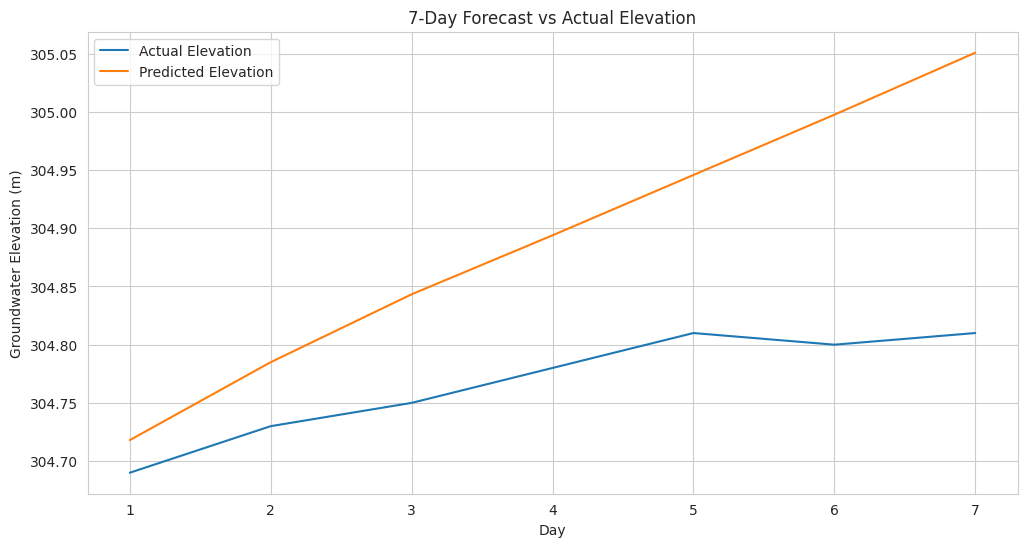

In [ ]:
# Graph 7 day forecast against actual elevation
y_test_lm_7days = test['groundwater_water_level_elevation_m_asl'].iloc[:7]

plt.figure(figsize=(12, 6))
sns.lineplot(x=range(1, 8), y=y_test_lm_7days, label='Actual Elevation')
sns.lineplot(x=range(1, 8), y=predicted_elevations, label='Predicted Elevation')
plt.title('7-Day Forecast vs Actual Elevation')
plt.xlabel('Day')
plt.ylabel('Groundwater Elevation (m)')
plt.legend()
plt.show()

In [ ]:
days7_mse = mean_squared_error(y_test_lm_7days, predicted_elevations)
print(f"7 day forecast MSE: {days7_mse}")
days7_rmse = np.sqrt(days7_mse)
print(f"7 day forecast RMSE: {days7_rmse}")

7 day forecast MSE: 0.020137065290105647
7 day forecast RMSE: 0.14190512777946274


In [ ]:
# Calculate MSE and RMSE for all predictions on test data
list1 = []
list1.append(float(last_elevation))

list2 = test['groundwater_water_level_elevation_m_asl'][:-1].tolist()

previous_elevation = list1 + list2
previous_elevation = np.array(previous_elevation)

y_pred_lm_elevation = previous_elevation + y_pred_lm
y_test_lm_elevation = test['groundwater_water_level_elevation_m_asl']

# Calculate MSE and RMSE
mse_lm = mean_squared_error(y_test_lm_elevation, y_pred_lm_elevation)
print(f"MSE: {mse_lm}")
rmse_lm = np.sqrt(mse_lm)
print(f"RMSE: {rmse_lm}")


MSE: 0.03372571878500016
RMSE: 0.18364563372157847


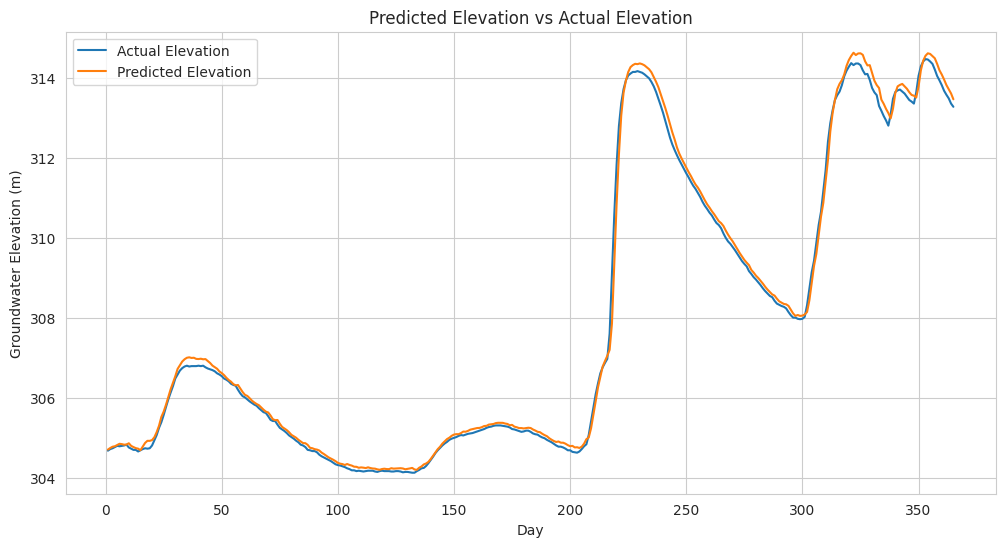

In [ ]:
# Plot Predicted vs Actual Elevation for 2023
plt.figure(figsize=(12, 6))

sns.lineplot(x=range(1, 366), y=y_test_lm_elevation, label='Actual Elevation')
sns.lineplot(x=range(1, 366), y=y_pred_lm_elevation, label='Predicted Elevation')

plt.title('Predicted Elevation vs Actual Elevation')
plt.xlabel('Day')
plt.ylabel('Groundwater Elevation (m)')
plt.legend()
plt.show()

### Model per Well
Fit a model for every well using a loop

In [ ]:
# Group by well
well_groups = df_daily.groupby('GROW_ID')

# Get a list of wells
wells = df_daily['GROW_ID'].unique().tolist()

# Create dictionaries to contain each well's actual groundwater elevation, predicted groundwater elevation, MSE, and model

actual_elevations_lm = dict()
predicted_elevations_lm = dict()
mse_per_well_lm = dict()
well_models = dict()
well_features = dict()

# Loop through each well
for well in wells:
  well_1 = well_groups.get_group(well).copy()
  well_1 = well_1.sort_values('date')

  # Create a sequential "time" variable:
  well_1['Time'] = np.arange(len(well_1.index))

  # Create a delta variable: change in groundwater elevation from yesterday to today
  well_1['delta'] = well_1['groundwater_water_level_elevation_m_asl'].diff()
  well_1 = well_1.dropna(subset=['delta'])

  # Training and Testing Split
  # Training Dataset: Jan 2019 - Dec 2022
  # Testing Dataset: 2023
  # Approximately a 80-20 split
  train = well_1.loc[well_1['date'] <= "2022-12-31", :]
  test = well_1.loc[well_1['date'] >= "2023-01-01", :]

  # Select numeric features only
  well_1 = well_1.select_dtypes(include='number')

  # Which ones only have one unique value (constant)
  col_to_drop = well_1.loc[:, well_1.nunique() == 1].columns

  well_1.drop(columns=col_to_drop, inplace=True)
  # Drop columns which have been used to create other features
  # Also remove "level_anomaly" which contains information about that day's actual elevation
  well_1.drop(columns=['year', 'precipitation_mswep_mm_year-1', 'precipitation_gpcc_mm_year-1', 'potential_evapotranspiration_era5_mm_year-1', 'potential_evapotranspiration_gleam_mm_year-1', 'level_anomaly', 'level_lag_1', 'level_lag_7', 'level_lag_30', 'level_diff_7'], inplace=True)
  # Note that lag features have also been dropped

  # Select features for training and testing datasets
  train = train[well_1.columns]
  test = test[well_1.columns]

  y_train_lm = train['delta']
  X_train_lm = train.drop(columns=['groundwater_water_level_elevation_m_asl', 'delta'])
  y_test_lm = test['delta']
  X_test_lm = test.drop(columns=['groundwater_water_level_elevation_m_asl', 'delta'])

  # Add features to dictionary
  well_features[well] = X_train_lm.columns

  # Scale features
  scaler_lm = MinMaxScaler()
  X_train_lm_scaled = scaler_lm.fit_transform(X_train_lm)
  X_test_lm_scaled = scaler_lm.transform(X_test_lm)

  # Create a linear regression model
  lm_model = LinearRegression()

  # Fit the model
  lm_model.fit(X_train_lm_scaled, y_train_lm)

  # Make predictions
  y_pred_lm = lm_model.predict(X_test_lm_scaled)

  # Add model to dictionary
  well_models[well] = lm_model

  last_elevation = train['groundwater_water_level_elevation_m_asl'].iloc[-1]
  # Calculate MSE and RMSE for all predictions on test data
  # Get the last elevation value from training data
  list1 = []
  list1.append(float(last_elevation))
  # Get elevation values for 364 days
  list2 = test['groundwater_water_level_elevation_m_asl'][:-1].tolist()

  previous_elevation = list1 + list2
  previous_elevation = np.array(previous_elevation)
  # Converting from delta predictions to actual groundwater elevation predictions
  y_pred_lm_elevation = previous_elevation + y_pred_lm
  y_test_lm_elevation = test['groundwater_water_level_elevation_m_asl']

  # Update dictionaries
  actual_elevations_lm[well] = y_test_lm_elevation
  predicted_elevations_lm[well] = y_pred_lm_elevation

  # Calculate MSE and RMSE
  mse_lm = mean_squared_error(y_test_lm_elevation, y_pred_lm_elevation)

  # Update MSE dictionary
  mse_per_well_lm[well] = mse_lm

In [ ]:
for key, value in mse_per_well_lm.items():
  print(f"Well: {key}, RMSE: {np.sqrt(value)}")
print("-"*50)
rmse_lm = np.sqrt(list(mse_per_well_lm.values()))
avg_rmse_lm = np.mean(rmse_lm)
print(f"Average RMSE across all wells: {avg_rmse_lm}")

Well: GROW-18108201772, RMSE: 0.18364563372157847
Well: GROW-18108286252, RMSE: 0.1118921038427681
Well: GROW-18108328402, RMSE: 0.30027916932576115
Well: GROW-18108370783, RMSE: 0.09748763928818856
Well: GROW-18108413683, RMSE: 0.15463599173566098
Well: GROW-18108456083, RMSE: 0.0855779997811046
Well: GROW-18108540984, RMSE: 0.09150978643495028
Well: GROW-18108795755, RMSE: 0.11436738255698034
Well: GROW-18108838445, RMSE: 0.0935114224112244
Well: GROW-18108880826, RMSE: 0.07698462560329321
Well: GROW-18108966166, RMSE: 0.09197123021400287
Well: GROW-18109008376, RMSE: 0.08089180552488226
Well: GROW-18109055197, RMSE: 0.06288710074973035
Well: GROW-18109140047, RMSE: 0.05305857886426522
Well: GROW-18109182587, RMSE: 0.22425784016878017
Well: GROW-18109228528, RMSE: 0.06643657974737172
Well: GROW-18109271148, RMSE: 0.0767687209470911
Well: GROW-18109313058, RMSE: 0.0811665385910304
Well: GROW-18109439739, RMSE: 0.164244666281591
Well: GROW-18109482609, RMSE: 0.4194310967236377
Well: GR

In [ ]:
# Feature Importance

feature_importance = dict()
for key, model in well_models.items():
  # For each well, sort the features in descending order by magnitude of coefficient
  feature_importance[key] = pd.Series(np.abs(model.coef_), index=well_features[key]).sort_values(ascending=False)

In [ ]:
top_5_features = dict()
for key, value in feature_importance.items():
  # For each well, obtain top 5 features
  top5 = value.index.tolist()[0:5]
  for feature in top5:
    # If feature exists in dictionary already, increase count
    if feature in top_5_features:
      top_5_features[feature] += 1
    # Else, start count at 1
    else:
      top_5_features[feature] = 1

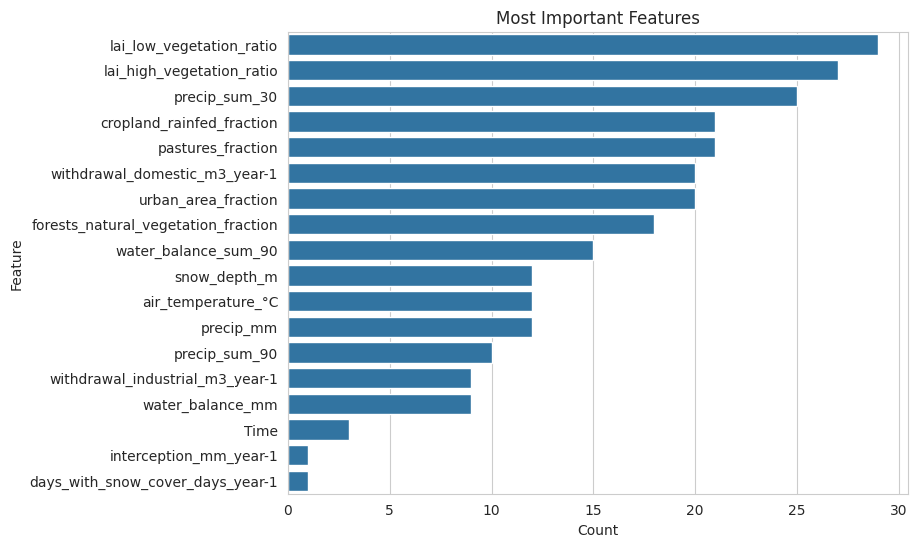

In [ ]:
x = pd.Series(top_5_features.values())
y = pd.Series(top_5_features.keys())
# Create an order column that sorts y based on values in x
sort_indices = x.sort_values(ascending=False).index
order = y.loc[sort_indices]

plt.figure(figsize=(8, 6))

sns.barplot(x=x, y=y, order=order)
plt.title("Most Important Features")
plt.xlabel("Count")
plt.ylabel("Feature")
plt.show()


The above visualization shows how many wells had a certain feature in their top 5 features. So across wells, the top 5 features, in order, are:
1. "lai_low_vegetation_ratio" (29 wells)
2. "lai_high_vegetation_ratio" (27 wells)
3. "precip_sum_30" (25 wells)
4. "cropland_rainfed_fraction" (21 wells)
5. "pastures_fraction" (21 wells)


## DECISION TREE MODELS

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

In [ ]:
corr_matrix = df_daily.corr(numeric_only=True)
label_corr = corr_matrix['groundwater_water_level_elevation_m_asl'].abs().sort_values(ascending=False)
print(label_corr.head(20))

groundwater_water_level_elevation_m_asl        1.000000
level_lag_1                                    0.999981
level_lag_7                                    0.999599
groundwater_mean_m                             0.998960
level_lag_30                                   0.998960
groundwater_median_m                           0.998899
ground_elevation_merit_m_asl                   0.963624
latitude                                       0.852334
longitude                                      0.723884
days_with_snow_cover_days_year-1               0.574849
trend_slope_m_year-1                           0.424330
distance_to_cluster_center_km                  0.407218
cropland_rainfed_fraction                      0.366652
potential_evapotranspiration_era5_mm_year-1    0.354841
topographic_slope_degree                       0.353900
lai_low_vegetation_ratio                       0.277418
forests_natural_vegetation_fraction            0.264569
trend_direction_no trend                       0

In [ ]:
y = df_daily['groundwater_water_level_elevation_m_asl']
X = df_daily.drop(columns=['groundwater_water_level_elevation_m_asl'])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=123)

In [ ]:
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X, y, test_size=0.3, random_state=123)
top_correlated_features = label_corr.index[1:11]
X_train_filtered = X_train_dt[top_correlated_features]
X_test_filtered = X_test_dt[top_correlated_features]
dt_regressor = DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=123)
dt_regressor.fit(X_train_filtered, y_train_dt)
y_pred_dt = dt_regressor.predict(X_test_filtered)
mse_dt = mean_squared_error(y_test_dt, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
print(f"\nDecision Tree Regressor MSE: {mse_dt:.4f}")
print(f"Decision Tree Regressor RMSE: {rmse_dt:.4f} meters")


Decision Tree Regressor MSE: 0.0608
Decision Tree Regressor RMSE: 0.2466 meters


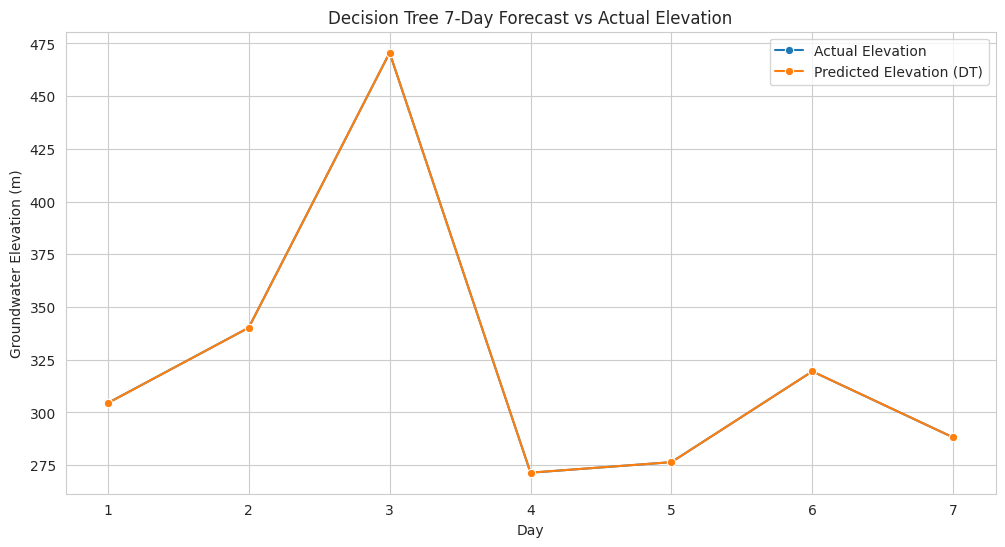

DT 7-day Forecast MSE: 0.0007
DT 7-day Forecast RMSE: 0.0266 meters


In [ ]:
X_test_7days = X_test_filtered.iloc[:7]
y_test_dt_7days = y_test_dt.iloc[:7]
predicted_elevations_dt = dt_regressor.predict(X_test_7days)
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(1, 8), y=y_test_dt_7days.values, label='Actual Elevation', marker='o')
sns.lineplot(x=range(1, 8), y=predicted_elevations_dt, label='Predicted Elevation (DT)', marker='o')
plt.title('Decision Tree 7-Day Forecast vs Actual Elevation')
plt.xlabel('Day')
plt.ylabel('Groundwater Elevation (m)')
plt.legend()
plt.grid(True)
plt.show()
dt_7day_mse = mean_squared_error(y_test_dt_7days, predicted_elevations_dt)
print(f"DT 7-day Forecast MSE: {dt_7day_mse:.4f}")
print(f"DT 7-day Forecast RMSE: {np.sqrt(dt_7day_mse):.4f} meters")

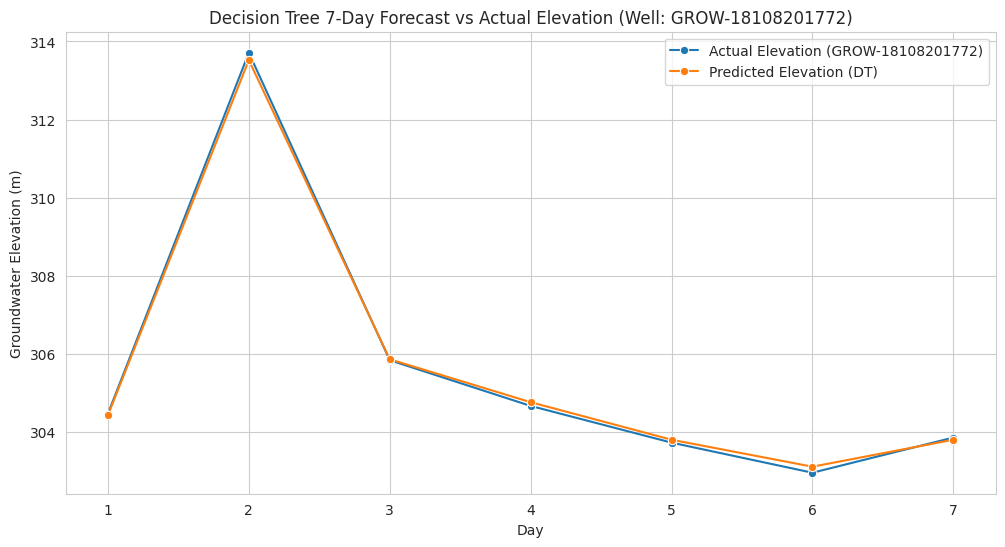

Well GROW-18108201772 DT 7-day Forecast MSE: 0.0112
Well GROW-18108201772 DT 7-day Forecast RMSE: 0.1061 meters


In [ ]:
well_id = 'GROW-18108201772'
well_test_mask = df_daily.loc[y_test_dt.index, 'GROW_ID'] == well_id
X_test_well = X_test_filtered[well_test_mask]
y_test_well = y_test_dt[well_test_mask]
X_test_well_7days = X_test_well.iloc[:7]
y_test_well_7days = y_test_well.iloc[:7]
predicted_elevations_well_dt = dt_regressor.predict(X_test_well_7days)
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(1, 8), y=y_test_well_7days.values, label='Actual Elevation (GROW-18108201772)', marker='o')
sns.lineplot(x=range(1, 8), y=predicted_elevations_well_dt, label='Predicted Elevation (DT)', marker='o')
plt.title(f'Decision Tree 7-Day Forecast vs Actual Elevation (Well: {well_id})')
plt.xlabel('Day')
plt.ylabel('Groundwater Elevation (m)')
plt.legend()
plt.grid(True)
plt.show()
dt_well_7day_mse = mean_squared_error(y_test_well_7days, predicted_elevations_well_dt)
print(f"Well {well_id} DT 7-day Forecast MSE: {dt_well_7day_mse:.4f}")
print(f"Well {well_id} DT 7-day Forecast RMSE: {np.sqrt(dt_well_7day_mse):.4f} meters")

/tmp/ipykernel_4424/3904269232.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dt_importances, x='Importance', y='Feature', palette='viridis')


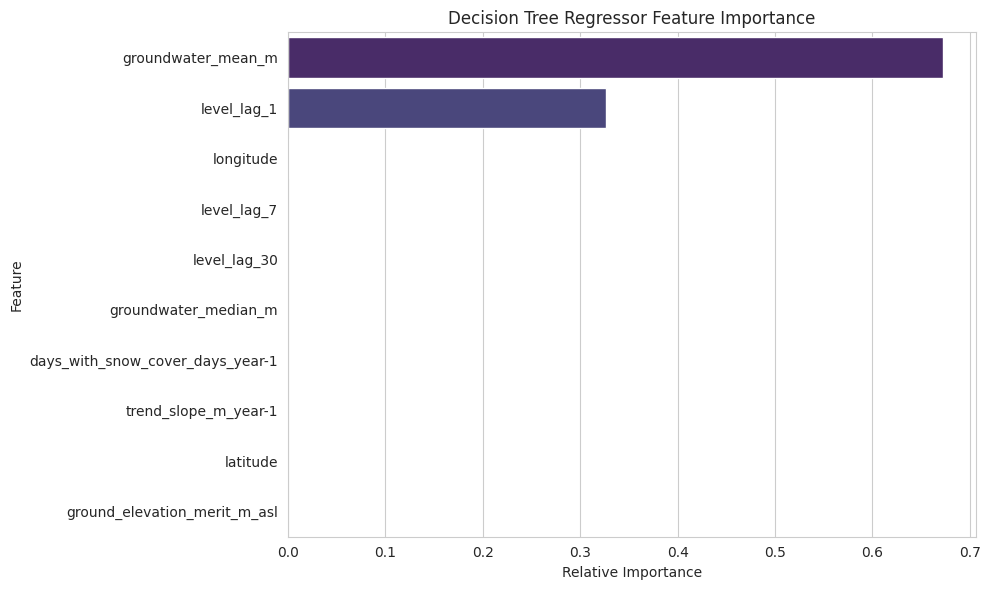

,Feature,Importance
2,groundwater_mean_m,6.727302e-01
0,level_lag_1,3.260180e-01
7,longitude,1.239020e-03
1,level_lag_7,9.910938e-06
3,level_lag_30,1.629720e-06
4,groundwater_median_m,1.100072e-06
8,days_with_snow_cover_days_year-1,9.286954e-08
9,trend_slope_m_year-1,7.516493e-08
6,latitude,4.039294e-08
5,ground_elevation_merit_m_asl,0.000000e+00


In [ ]:
importances = dt_regressor.feature_importances_
features_list = X_train_filtered.columns
dt_importances = pd.DataFrame({
    'Feature': features_list,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(data=dt_importances, x='Importance', y='Feature', palette='viridis')
plt.title('Decision Tree Regressor Feature Importance')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
display(dt_importances)

## LSTM: Long Short Term Memory

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
torch.manual_seed(42)
np.random.seed(42)

# copy of the daily data for the lstm and then sorting by well and date accordingly
lstm_df = df_daily.sort_values(['GROW_ID', 'date']).reset_index(drop=True)

# lvl moved since yesterday
lstm_df['change_1'] = lstm_df[target] - lstm_df['level_lag_1']

# doing the level vs the well's normal level, but in here the mean only uses the train years 2019-2021)
train_mean = lstm_df[lstm_df['date'] < '2022-01-01'].groupby('GROW_ID')[target].mean()
lstm_df['anomaly_train'] = lstm_df[target] - lstm_df['GROW_ID'].map(train_mean)

# 10 features, most of them come from our feature engineering
features = ['change_1',
            'level_diff_7',
            'anomaly_train',
            'precip_mm',
            'precip_sum_30',
            'precip_sum_90',
            'water_balance_mm',
            'water_balance_sum_90',
            'air_temperature_°C',
            'is_recharge_season']
print('Here the missing values is', lstm_df[features].isna().sum().sum())

Here the missing values is 0


In [ ]:
# scale features to 0-1 instead of mean/std, lstm gates (sigmoid/tanh) work better with bounded input
# using only train rows so 2022 and 2023 dont leak in
is_train = lstm_df['date'] < '2022-01-01'
min_ = lstm_df.loc[is_train, features].min()
max_ = lstm_df.loc[is_train, features].max()
lstm_df[features] = (lstm_df[features] - min_) / (max_ - min_)

In [ ]:
# windows: 30 days in, next 7 days out, one well at a time
# doing one well at a time so a window never mixes 2 different wells
X_seq = []
y_seq = []
window_info = []

for well in lstm_df['GROW_ID'].unique():
  well_df = lstm_df[lstm_df['GROW_ID'] == well]
  feats = well_df[features].values
  level = well_df[target].values
  dates = well_df['date'].values

  for i in range(len(well_df) - 36):
    x = feats[i:i+30]
    today = level[i+29]
    next_7 = level[i+30:i+37]
    X_seq.append(x)
    y_seq.append(next_7 - today)
    window_info.append([well, dates[i+29], dates[i+36], today])

X_seq = np.array(X_seq, dtype='float32')
y_seq = np.array(y_seq, dtype='float32')
window_info = pd.DataFrame(window_info, columns=['GROW_ID', 'date', 'end_date', 'level_today'])

print(X_seq.shape, y_seq.shape)

(93280, 30, 10) (93280, 7)


In [ ]:
# split by year, train = 2019-2021, val = 2022, test = 2023
# end_date makes sure the 7 predicted days stay inside the same year
train_mask = (window_info['end_date'] < '2022-01-01').values
val_mask = ((window_info['date'] >= '2022-01-01') & (window_info['end_date'] < '2023-01-01')).values
test_mask = (window_info['date'] >= '2023-01-01').values

X_train = torch.tensor(X_seq[train_mask])
y_train = torch.tensor(y_seq[train_mask])
X_val = torch.tensor(X_seq[val_mask])
y_val = torch.tensor(y_seq[val_mask])
X_test = torch.tensor(X_seq[test_mask])
y_test = y_seq[test_mask]   # keeping this one numpy, using it for rmse later

print(len(X_train), len(X_val), len(X_test))

train_data = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_data, batch_size=256, shuffle=True)

54590 18974 18974


In [ ]:
# lstm reads the 30 days in order, then a linear layer turns the last day into 7 predictions
class LSTMModel(nn.Module):
  def __init__(self, n_features, hidden_size):
    super().__init__()
    self.lstm = nn.LSTM(n_features, hidden_size, batch_first=True)
    self.linear = nn.Linear(hidden_size, 7)

  def forward(self, x):
    out, _ = self.lstm(x)
    out = out[:, -1, :]
    return self.linear(out)

lstm_model = LSTMModel(n_features=10, hidden_size=64)
print(lstm_model)

LSTMModel(
  (lstm): LSTM(10, 64, batch_first=True)
  (linear): Linear(in_features=64, out_features=7, bias=True)
)


epoch 1 train 0.0786 val 0.0511
epoch 2 train 0.0736 val 0.0503
epoch 3 train 0.0708 val 0.0508
epoch 4 train 0.0694 val 0.0521
epoch 5 train 0.0683 val 0.0528
epoch 6 train 0.0672 val 0.0522
epoch 7 train 0.0664 val 0.0556
stopping early


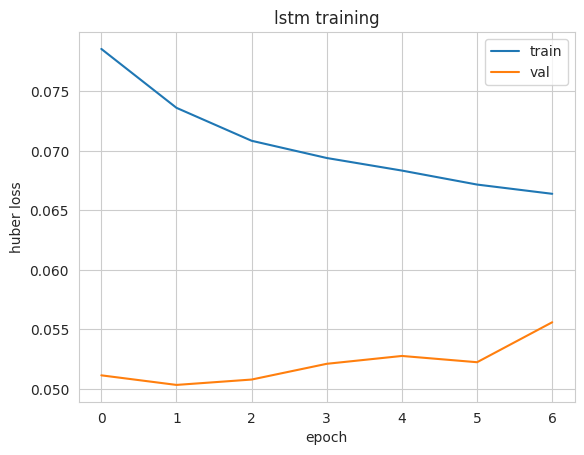

In [ ]:
# huber loss is like mse but big outlier jumps count less, a few wells jump a lot in one day
loss_fn = nn.HuberLoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.0003)

train_losses = []
val_losses = []
best_val = 999999
epochs_no_improve = 0

for epoch in range(50):
  lstm_model.train()
  total_loss = 0
  for xb, yb in train_loader:
    optimizer.zero_grad()
    pred = lstm_model(xb)
    loss = loss_fn(pred, yb)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * len(xb)
  train_loss = total_loss / len(X_train)

  lstm_model.eval()
  with torch.no_grad():
    val_loss = loss_fn(lstm_model(X_val), y_val).item()

  train_losses.append(train_loss)
  val_losses.append(val_loss)
  print('epoch', epoch + 1, 'train', round(train_loss, 4), 'val', round(val_loss, 4))

  # early stopping: save the best one, stop if val doesnt improve for 5 epochs
  if val_loss < best_val:
    best_val = val_loss
    epochs_no_improve = 0
    torch.save(lstm_model.state_dict(), 'best_lstm.pt')
  else:
    epochs_no_improve += 1
  if epochs_no_improve == 5:
    print('stopping early')
    break

lstm_model.load_state_dict(torch.load('best_lstm.pt'))

plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val')
plt.title('lstm training')
plt.xlabel('epoch')
plt.ylabel('huber loss')
plt.legend()
plt.show()

In [ ]:
# testing on 2023, model never saw this year
lstm_model.eval()
with torch.no_grad():
  lstm_pred = lstm_model(X_test).numpy()

# rmse per day, persistence = guessing no change at all
lstm_rmse = []
persistence_rmse = []
for d in range(7):
  lstm_rmse.append(np.sqrt(np.mean((lstm_pred[:, d] - y_test[:, d]) ** 2)))
  persistence_rmse.append(np.sqrt(np.mean(y_test[:, d] ** 2)))

results = pd.DataFrame({'day': range(1, 8), 'persistence': persistence_rmse, 'lstm': lstm_rmse})
results['better_%'] = (1 - results['lstm'] / results['persistence']) * 100
print(results.round(3))

# success criteria: within 30% of ground truth (20% stretch), averaged over the 7 days
level_today = window_info['level_today'][test_mask].values.reshape(-1, 1)
actual_level = level_today + y_test
predicted_level = level_today + lstm_pred
pct_error = np.mean(np.abs(predicted_level - actual_level) / actual_level, axis=1) * 100

print()
print('avg % error:', round(pct_error.mean(), 3))
print()
print('within 30%:', round((pct_error <= 30).mean() * 100, 1), '%')
print('within 20%:', round((pct_error <= 20).mean() * 100, 1), '%')

   day  persistence   lstm  better_%
0    1        0.273  0.296    -8.625
1    2        0.507  0.534    -5.292
2    3        0.707  0.729    -3.089
3    4        0.881  0.898    -1.925
4    5        1.034  1.051    -1.711
5    6        1.169  1.180    -0.879
6    7        1.290  1.302    -0.969

avg % error: 0.093

within 30%: 100.0 %
within 20%: 100.0 %


## Model evaluation

### 1-day-ahead RMSE comparison across all models:

               model  rmse_1day  persistence_1day  better_than_persistence_%
0  Linear Regression     0.1365            0.1361                    -0.2725
1      Decision Tree     0.1534            0.1361                   -12.6671
2               LSTM     0.1676            0.1371                   -22.2488


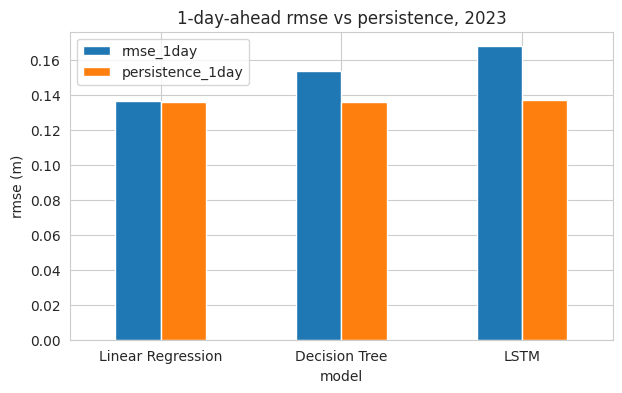

In [133]:
# 1-day-ahead RMSE on 2023, averaged per well, each model next to persistence (no change) on the same rows
test_days = df_daily[df_daily['date'] >= '2023-01-01']
train_days = df_daily[df_daily['date'] < '2023-01-01']
persist_err = test_days[target] - test_days['level_lag_1']
persist_rmse = np.sqrt((persist_err ** 2).groupby(test_days['GROW_ID']).mean()).mean()

# decision tree: same features + settings as the DT section, but train 2019-2022 / test 2023
# and predict the change from yesterday (a tree can't output smooth absolute elevations)
dt_change_model = DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=123)
dt_change_model.fit(train_days[top_correlated_features], train_days[target] - train_days['level_lag_1'])
dt_pred_2023 = test_days['level_lag_1'] + dt_change_model.predict(test_days[top_correlated_features])
dt_err = dt_pred_2023 - test_days[target]
dt_1day = np.sqrt((dt_err ** 2).groupby(test_days['GROW_ID']).mean()).mean()

# lstm: day 1 of each 7-day window in 2023 (its own rows, so its own persistence)
test_wells = window_info.loc[test_mask, 'GROW_ID'].values
lstm_err = pd.Series(lstm_pred[:, 0] - y_test[:, 0])
lstm_1day = np.sqrt((lstm_err ** 2).groupby(test_wells).mean()).mean()
lstm_persist = np.sqrt((pd.Series(y_test[:, 0]) ** 2).groupby(test_wells).mean()).mean()

comparison = pd.DataFrame({
    'model': ['Linear Regression', 'Decision Tree', 'LSTM'],
    'rmse_1day': [avg_rmse_lm, dt_1day, lstm_1day],
    'persistence_1day': [persist_rmse, persist_rmse, lstm_persist],
})
comparison['better_than_persistence_%'] = (1 - comparison['rmse_1day'] / comparison['persistence_1day']) * 100
print(comparison.round(4))

comparison.plot(x='model', y=['rmse_1day', 'persistence_1day'], kind='bar', figsize=(7, 4))
plt.title('1-day-ahead rmse vs persistence, 2023')
plt.ylabel('rmse (m)')
plt.xticks(rotation=0)
plt.show()

**Takeaway:** on 1-day-ahead forecasts for 2023 (all 53 wells, RMSE averaged per well), none of the three models beats persistence (predicting no change from yesterday). Linear regression ties it (-0.3%), the decision tree is 12.7% worse and the LSTM is 22.2% worse. Daily groundwater levels barely move from one day to the next, so persistence is a very strong baseline at this horizon.

### 7-day forecast (for well 'GROW-18108201772') RMSE comparison across all models:

In [162]:
# 1. Calculate the 7-day persistence error
# (Actual level today minus the actual level 7 days ago)
persist_well = df_daily.groupby('GROW_ID').get_group('GROW-18108201772')
persist_target = persist_well.loc[persist_well['date'] == "2023-01-07", "groundwater_water_level_elevation_m_asl"].values[0]
persist_lag7 = persist_well.loc[persist_well['date'] == "2022-12-31", "groundwater_water_level_elevation_m_asl"].values[0]
persist_7day_err = persist_target - persist_lag7

# 2. Calculate RMSE grouped by well, then average across all wells
persist_7day_rmse = np.sqrt((persist_7day_err ** 2).mean())

# For LSTM, the persistence is:
idx = window_info[(window_info['GROW_ID'] == 'GROW-18108201772') & (window_info['date'] == "2023-01-01")].index[0]
persist_7day_lstm = y_seq[idx, 6]

# Linear Regression 7 day forecast RMSE: days7_rmse
# Decision Tree 7 day forecast RMSE: np.sqrt(dt_well_7day_mse)
# LSTM 7 day forecast RMSE:
# For LSTM, no sliding window for January 1st, 2023 - January 7th, 2023, so we use Jan 2nd - Jan 8th for comparison instead.
test_window_info = window_info[test_mask].reset_index(drop=True)

match_mask = (
    (test_window_info['GROW_ID'] == 'GROW-18108201772') &
    (test_window_info['date'] == '2023-01-01')
)

idx2 = test_window_info[match_mask].index[0]

actual_delta = y_test[idx2, :]
predicted_delta = lstm_pred[idx2, :]

lstm_days7_rmse = np.sqrt(np.mean((actual_delta - predicted_delta) ** 2))


               Model  rmse_7day  persistence_7day  better_than_persistence_%
0  Linear Regression     0.1419              0.16                    11.3093
1      Decision Tree     0.1061              0.16                    33.7186
2               LSTM     0.1136              0.13                    12.6334


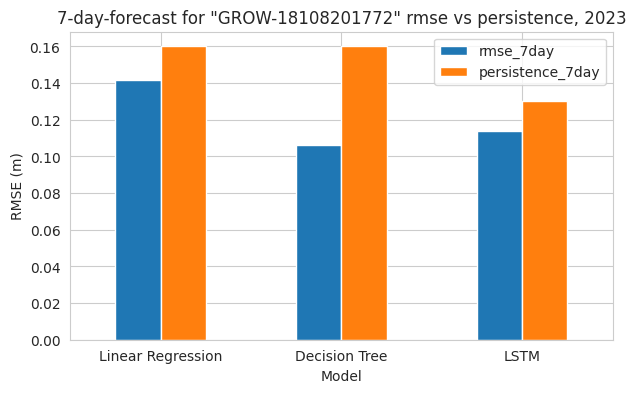

In [164]:
days7_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'LSTM'],
    'rmse_7day': [days7_rmse, np.sqrt(dt_well_7day_mse), lstm_days7_rmse],
    'persistence_7day': [persist_7day_rmse, persist_7day_rmse, persist_7day_lstm],
})

days7_comparison['better_than_persistence_%'] = (1 - days7_comparison['rmse_7day'] / days7_comparison['persistence_7day']) * 100
print(days7_comparison.round(4))

days7_comparison.plot(x='Model', y=['rmse_7day', 'persistence_7day'], kind='bar', figsize=(7, 4))
plt.title('7-day-forecast for "GROW-18108201772" rmse vs persistence, 2023')
plt.ylabel('RMSE (m)')
plt.xticks(rotation=0)
plt.show()